# Filtro de mediana

Comparar k = 3, 5, 7, 9 e escolher o do pipeline.


In [1]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

raiz do projeto: /home/isadora/Documentos/ProcessIMg


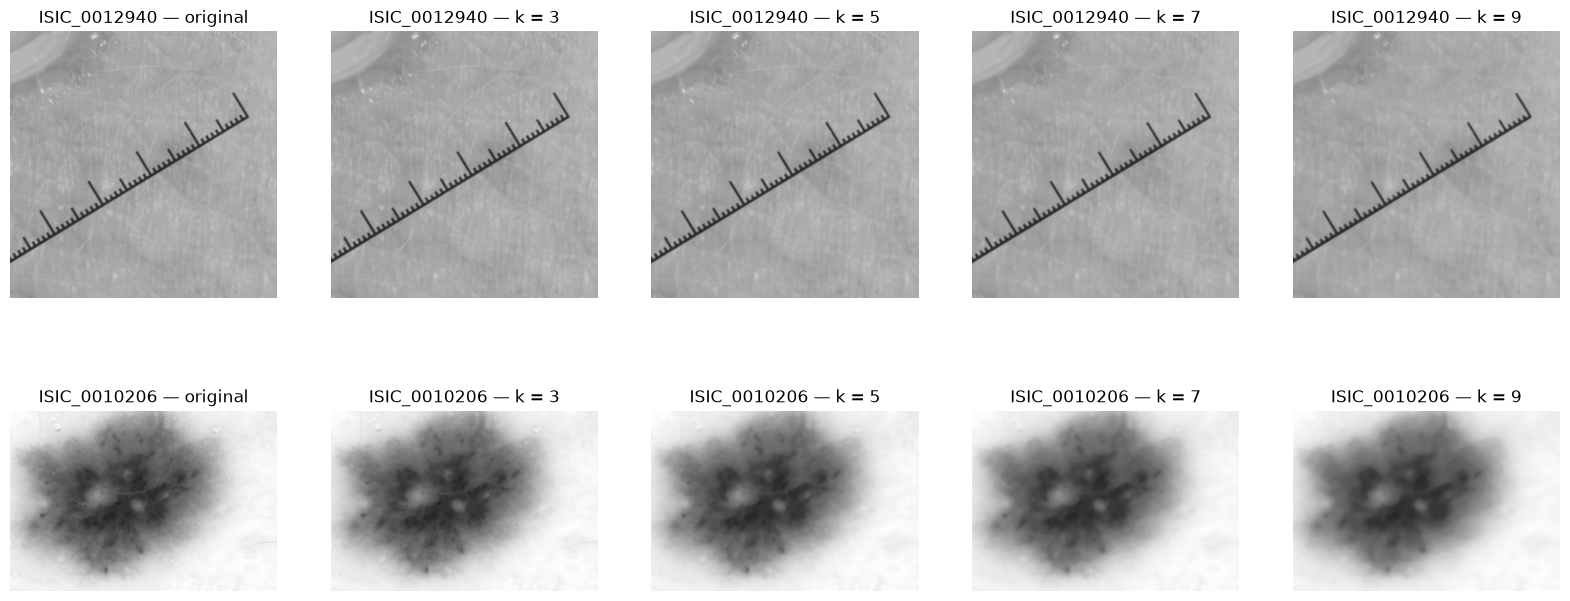

In [2]:
from src.preprocessamento import para_cinza
from src.filtragem import filtrar_mediana

alvo = PASTA_RESULTADOS / "filtradas"

# (nome, recorte do zoom em linhas/colunas) — zoom é essencial para VER pelos/ruído
casos = [
    ("ISIC_0012940.jpg", np.s_[1400:2200, 2500:3300]),   # difícil: régua + textura da pele
    ("ISIC_0010206.jpg", np.s_[250:520, 350:750]),       # fácil: borda da lesão
]

fig, axes = plt.subplots(len(casos), 5, figsize=(20, 4 * len(casos)))
for i, (nome, recorte) in enumerate(casos):
    cinza = para_cinza(carregar_imagem(PASTA_IMAGENS / nome))
    nome_curto = Path(nome).stem

    versoes = [cinza] + [filtrar_mediana(cinza, k) for k in (3, 5, 7, 9)]
    titulos = ["original", "k = 3", "k = 5", "k = 7", "k = 9"]

    for j, (img, tit) in enumerate(zip(versoes, titulos)):
        axes[i, j].imshow(img[recorte], cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(f"{nome_curto} — {tit}")
        axes[i, j].axis("off")

fig.savefig(alvo / "comparacao_mediana.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)